# 08 — Distance-band context signatures

Using frozen losses \(L_8,L_{32},L_{128},L_{256}\), define:

\[
\Delta_{8\to32}=L_8-L_{32},\quad
\Delta_{32\to128}=L_{32}-L_{128},\quad
\Delta_{128\to256}=L_{128}-L_{256}.
\]

This notebook tests whether generator-specific information is localized to particular
context-distance bands, whether that allocation adds attribution value beyond the two
endpoint losses \(L_8,L_{256}\), whether it transfers across domains, and whether it
aligns with recurrence features.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, accuracy_score, f1_score

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
DATA, RESULTS, FIGURES = ROOT/"data", ROOT/"results", ROOT/"figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

RAW_PATH = DATA/"raw"/"ghostbuster_detector_pool.parquet"
CTX_PATH = RESULTS/"ghostbuster_detector_context.parquet"
F_PATH = RESULTS/"ghostbuster_detector_frontloading.parquet"

raw = pd.read_parquet(RAW_PATH).copy()
ctx = pd.read_parquet(CTX_PATH).copy()

machine = raw[raw["generator"].isin(["gpt","claude"])].copy()
machine["pair_id"] = machine["domain"].astype(str)+"::"+machine["group_id"].astype(str)
pc = machine.groupby("pair_id")["generator"].agg(["size","nunique"])
valid = pc.index[(pc["size"]==2)&(pc["nunique"]==2)]
machine = machine[machine["pair_id"].isin(valid)].copy()

print("paired source groups:", machine["pair_id"].nunique())
print("documents:", len(machine))


paired source groups: 3000
documents: 6000


## Strong transparent style controls


In [2]:
WORD_RE = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")
SENTENCE_SPLIT_RE = re.compile(r"(?<=[.!?])\s+")
FUNCTION_WORDS = {
"a","about","above","after","again","against","all","am","an","and","any","are","as","at","be","because",
"been","before","being","below","between","both","but","by","can","could","did","do","does","doing","down",
"during","each","few","for","from","further","had","has","have","having","he","her","here","hers","herself",
"him","himself","his","how","i","if","in","into","is","it","its","itself","just","me","more","most","my",
"myself","no","nor","not","now","of","off","on","once","only","or","other","our","ours","ourselves","out",
"over","own","same","she","should","so","some","such","than","that","the","their","theirs","them",
"themselves","then","there","these","they","this","those","through","to","too","under","until","up","very",
"was","we","were","what","when","where","which","while","who","whom","why","will","with","would","you",
"your","yours","yourself","yourselves"
}
PUNCT_CHARS=set(".,;:!?-—()[]{}\"'")

def lexical_entropy(tokens):
    if not tokens: return np.nan
    p = pd.Series(tokens).value_counts(normalize=True).to_numpy()
    return float(-(p*np.log2(p)).sum())

def style_feats(text):
    text=str(text)
    orig=WORD_RE.findall(text)
    toks=[t.lower() for t in orig]
    n=len(toks)
    if n==0:
        return {
            "mean_sentence_words":np.nan,"type_token_ratio":np.nan,"function_word_rate":np.nan,
            "word_count":0,"mean_word_length":np.nan,"lexical_entropy":np.nan,
            "punctuation_rate":np.nan,"digit_rate":np.nan,"uppercase_token_rate":np.nan
        }
    sent_counts=[len(WORD_RE.findall(s)) for s in SENTENCE_SPLIT_RE.split(text.strip())]
    sent_counts=[x for x in sent_counts if x>0]
    return {
        "mean_sentence_words":float(np.mean(sent_counts)) if sent_counts else float(n),
        "type_token_ratio":len(set(toks))/n,
        "function_word_rate":sum(t in FUNCTION_WORDS for t in toks)/n,
        "word_count":n,
        "mean_word_length":float(np.mean([len(t) for t in toks])),
        "lexical_entropy":lexical_entropy(toks),
        "punctuation_rate":sum(ch in PUNCT_CHARS for ch in text)/max(len(text),1),
        "digit_rate":sum(ch.isdigit() for ch in text)/max(len(text),1),
        "uppercase_token_rate":sum(len(t)>1 and t.isupper() for t in orig)/n,
    }

style = pd.DataFrame([
    {"row_id":r.row_id, **style_feats(r.text)}
    for r in machine[["row_id","text"]].itertuples(index=False)
])

STYLE_STRONG = [
    "mean_sentence_words","type_token_ratio","function_word_rate","word_count",
    "mean_word_length","lexical_entropy","punctuation_rate","digit_rate","uppercase_token_rate"
]


## Build bandwise gains and saturation ratio


In [3]:
work=(machine[["row_id","pair_id","domain","group_id","generator","text"]]
      .merge(ctx[["row_id","context_loss_8","context_loss_32","context_loss_128","context_loss_256"]],
             on="row_id",how="left",validate="one_to_one")
      .merge(style,on="row_id",how="left",validate="one_to_one"))

work["gain_8_32"]=work["context_loss_8"]-work["context_loss_32"]
work["gain_32_128"]=work["context_loss_32"]-work["context_loss_128"]
work["gain_128_256"]=work["context_loss_128"]-work["context_loss_256"]
work["gain_8_128"]=work["context_loss_8"]-work["context_loss_128"]
work["saturation_ratio"]=work["gain_128_256"]/(np.abs(work["gain_8_128"])+1e-8)

needed=["context_loss_8","context_loss_32","context_loss_128","context_loss_256",
        "gain_8_32","gain_32_128","gain_128_256","saturation_ratio",*STYLE_STRONG]
work=work.dropna(subset=needed).copy()

complete=(work.groupby("pair_id")["generator"].agg(["size","nunique"])
          .query("size==2 and nunique==2").index)
work=work[work["pair_id"].isin(complete)].copy()
work["label"]=(work["generator"]=="claude").astype(int)

print("complete pairs:",work["pair_id"].nunique())
print(work.groupby(["domain","generator"]).size())


complete pairs: 2860
domain  generator
essay   claude       1000
        gpt          1000
reuter  claude        982
        gpt           982
wp      claude        878
        gpt           878
dtype: int64


# Part I — Generator differences by band


In [4]:
BANDS=["gain_8_32","gain_32_128","gain_128_256","saturation_ratio"]

display(work.groupby("generator")[BANDS].agg(["mean","std","median","count"]))

paired_rows=[]
for feature in BANDS:
    w=work.pivot(index=["domain","pair_id"],columns="generator",values=feature).dropna()
    d=w["claude"]-w["gpt"]
    sd=d.std(ddof=1)
    paired_rows.append({
        "feature":feature,"n_pairs":len(d),"mean_claude_minus_gpt":d.mean(),
        "median_claude_minus_gpt":d.median(),"sd":sd,
        "paired_dz":d.mean()/sd if sd>0 else np.nan,
        "positive_fraction":(d>0).mean()
    })

paired_summary=pd.DataFrame(paired_rows)
display(paired_summary)
paired_summary.to_csv(RESULTS/"distance_band_context_signatures_generator_differences.csv",index=False)


gain_8_32                           gain_32_128                      \
               mean       std    median count        mean       std    median   
generator                                                                       
claude     0.835255  0.580819  0.769621  2860    0.438734  0.485802  0.346373   
gpt        0.900966  0.592565  0.848553  2860    0.516523  0.515548  0.423886   

                gain_128_256                           saturation_ratio  \
          count         mean       std    median count             mean   
generator                                                                 
claude     2860     0.175109  0.282715  0.116639  2860         0.461493   
gpt        2860     0.161884  0.277699  0.109460  2860         0.552302   

                                      
                 std    median count  
generator                             
claude      3.876766  0.092877  2860  
gpt        16.968535  0.077539  2860

,feature,n_pairs,mean_claude_minus_gpt,median_claude_minus_gpt,sd,paired_dz,positive_fraction
0,gain_8_32,2860,-0.065711,-0.059082,0.830447,-0.079127,0.467832
1,gain_32_128,2860,-0.077788,-0.071389,0.711547,-0.109323,0.452448
2,gain_128_256,2860,0.013225,0.013879,0.399616,0.033093,0.517133
3,saturation_ratio,2860,-0.090809,0.016548,17.417573,-0.005214,0.526224


# Part II — Attribution beyond endpoint losses

The baseline already contains \(L_8\) and \(L_{256}\), so total \(8\to256\) gain is fixed.
Any improvement from a band feature means the **allocation** of gain across distance scales
contains additional source information.


In [5]:
BEND=["context_loss_8","context_loss_256",*STYLE_STRONG]

FEATURE_SETS={
    "Bend":BEND,
    "Bend+G8_32":[*BEND,"gain_8_32"],
    "Bend+G32_128":[*BEND,"gain_32_128"],
    "Bend+G128_256":[*BEND,"gain_128_256"],
    "Bend+Bands":[*BEND,"gain_8_32","gain_32_128","gain_128_256"],
    "Bend+Sat":[*BEND,"saturation_ratio"],
}

def make_clf():
    return Pipeline([
        ("scale",StandardScaler()),
        ("clf",LogisticRegression(class_weight="balanced",solver="lbfgs",max_iter=3000,random_state=0))
    ])

pair_ids=np.array(sorted(work["pair_id"].unique()))
rows=[]

for seed in range(20):
    rng=np.random.RandomState(seed)
    perm=rng.permutation(len(pair_ids))
    cut=int(.8*len(pair_ids))
    tr_ids=set(pair_ids[perm[:cut]])
    te_ids=set(pair_ids[perm[cut:]])
    tr=work[work["pair_id"].isin(tr_ids)]
    te=work[work["pair_id"].isin(te_ids)]
    for method,cols in FEATURE_SETS.items():
        m=make_clf(); m.fit(tr[cols],tr["label"])
        p=m.predict_proba(te[cols])[:,1]
        pred=(p>=.5).astype(int); y=te["label"].to_numpy()
        rows.append({
            "seed":seed,"method":method,
            "auroc":roc_auc_score(y,p),
            "balanced_accuracy":balanced_accuracy_score(y,pred),
            "accuracy":accuracy_score(y,pred),
            "f1":f1_score(y,pred)
        })

attrib=pd.DataFrame(rows)
attrib.to_csv(RESULTS/"distance_band_context_signatures_attribution_splits.csv",index=False)
display(attrib.groupby("method")[["auroc","balanced_accuracy","f1"]].mean().sort_values("auroc",ascending=False))


,auroc,balanced_accuracy,f1
method,,,
Bend+G128_256,0.890560,0.809047,0.812249
Bend+Bands,0.890416,0.808960,0.812077
Bend+G8_32,0.890324,0.806906,0.810303
Bend,0.890215,0.805114,0.808630
Bend+G32_128,0.890005,0.806643,0.810196
Bend+Sat,0.889997,0.805201,0.808733


In [6]:
def delta_summary(df,a,b,metric="auroc"):
    w=df.pivot(index="seed",columns="method",values=metric)
    v=(w[a]-w[b]).to_numpy()
    return {
        "comparison":f"{a} vs {b}","metric":metric,
        "mean_delta":v.mean(),"median_delta":np.median(v),
        "q25":np.quantile(v,.25),"q75":np.quantile(v,.75),
        "min":v.min(),"max":v.max(),"positive":int((v>0).sum()),"n":len(v)
    }

summ=[]
for a in ["Bend+G8_32","Bend+G32_128","Bend+G128_256","Bend+Bands","Bend+Sat"]:
    for metric in ["auroc","balanced_accuracy","f1"]:
        summ.append(delta_summary(attrib,a,"Bend",metric))
attrib_summary=pd.DataFrame(summ)
attrib_summary.to_csv(RESULTS/"distance_band_context_signatures_attribution_summary.csv",index=False)
display(attrib_summary)


,comparison,metric,mean_delta,median_delta,q25,q75,min,max,positive,n
0,Bend+G8_32 vs Bend,auroc,0.000109,0.000153,0.000006,0.000198,-0.000348,0.000361,16,20
1,Bend+G8_32 vs Bend,balanced_accuracy,0.001792,0.001748,0.000874,0.003497,-0.001748,0.005245,16,20
2,Bend+G8_32 vs Bend,f1,0.001672,0.001376,0.000619,0.002767,-0.001381,0.005172,16,20
3,Bend+G32_128 vs Bend,auroc,-0.000210,0.000002,-0.000449,0.000106,-0.001421,0.000248,10,20
4,Bend+G32_128 vs Bend,balanced_accuracy,0.001530,0.000874,0.000000,0.002841,-0.001748,0.006119,14,20
5,Bend+G32_128 vs Bend,f1,0.001566,0.001649,0.000269,0.003174,-0.002880,0.005478,15,20
6,Bend+G128_256 vs Bend,auroc,0.000345,0.000306,-0.000193,0.001018,-0.001177,0.001443,13,20
7,Bend+G128_256 vs Bend,balanced_accuracy,0.003934,0.003934,0.001530,0.006993,-0.001748,0.009615,16,20
8,Bend+G128_256 vs Bend,f1,0.003618,0.003933,0.001267,0.005739,-0.002034,0.008272,17,20
9,Bend+Bands vs Bend,auroc,0.000201,0.000310,-0.000225,0.000804,-0.001345,0.001427,13,20


# Part III — Held-out-domain transfer


In [7]:
LABELS={"essay":"Essay","reuter":"Reuters","wp":"Wikipedia"}
rows=[]

for held in ["essay","reuter","wp"]:
    tr=work[work["domain"]!=held]
    te=work[work["domain"]==held]
    for method,cols in FEATURE_SETS.items():
        m=make_clf(); m.fit(tr[cols],tr["label"])
        p=m.predict_proba(te[cols])[:,1]
        pred=(p>=.5).astype(int); y=te["label"].to_numpy()
        rows.append({
            "heldout_domain":held,"heldout_domain_label":LABELS[held],"method":method,
            "auroc":roc_auc_score(y,p),
            "balanced_accuracy":balanced_accuracy_score(y,pred),
            "f1":f1_score(y,pred)
        })

transfer=pd.DataFrame(rows)
transfer.to_csv(RESULTS/"distance_band_context_signatures_cross_domain.csv",index=False)
display(transfer.pivot(index="heldout_domain_label",columns="method",values="auroc"))


method,Bend,Bend+Bands,Bend+G128_256,Bend+G32_128,Bend+G8_32,Bend+Sat
heldout_domain_label,,,,,,
Essay,0.883335,0.883194,0.883964,0.882916,0.882720,0.883330
Reuters,0.871647,0.871399,0.871915,0.871127,0.871739,0.871713
Wikipedia,0.774063,0.775337,0.775947,0.773241,0.774075,0.772440


In [8]:
drows=[]
for held in ["essay","reuter","wp"]:
    s=transfer[transfer["heldout_domain"]==held].set_index("method")
    for method in ["Bend+G8_32","Bend+G32_128","Bend+G128_256","Bend+Bands","Bend+Sat"]:
        drows.append({
            "heldout_domain":held,"heldout_domain_label":LABELS[held],
            "comparison":f"{method} vs Bend",
            "delta_auroc":s.loc[method,"auroc"]-s.loc["Bend","auroc"],
            "delta_balanced_accuracy":s.loc[method,"balanced_accuracy"]-s.loc["Bend","balanced_accuracy"],
            "delta_f1":s.loc[method,"f1"]-s.loc["Bend","f1"]
        })
transfer_deltas=pd.DataFrame(drows)
transfer_deltas.to_csv(RESULTS/"distance_band_context_signatures_cross_domain_deltas.csv",index=False)
display(transfer_deltas.pivot(index="heldout_domain_label",columns="comparison",values="delta_auroc"))


comparison,Bend+Bands vs Bend,Bend+G128_256 vs Bend,Bend+G32_128 vs Bend,Bend+G8_32 vs Bend,Bend+Sat vs Bend
heldout_domain_label,,,,,
Essay,-0.000141,0.000629,-0.000419,-0.000615,-0.000005
Reuters,-0.000248,0.000269,-0.000520,0.000092,0.000066
Wikipedia,0.001274,0.001884,-0.000822,0.000012,-0.001623


# Part IV — Relation to recurrence features


In [9]:
if F_PATH.exists():
    fdf=pd.read_parquet(F_PATH).copy()
    candidate=["row_id","token_r_near","token_r_far","token_frontloading"]
    present=[c for c in candidate if c in fdf.columns]
    print("recurrence columns found:",present)
    if "row_id" in present and len(present)>1:
        joined=work.merge(fdf[present],on="row_id",how="left",validate="one_to_one")
        corr_cols=["gain_8_32","gain_32_128","gain_128_256","saturation_ratio"] + \
                  [c for c in ["token_r_near","token_r_far","token_frontloading"] if c in joined.columns]
        print("Pooled Pearson")
        display(joined[corr_cols].corr("pearson"))
        print("Pooled Spearman")
        display(joined[corr_cols].corr("spearman"))
        joined.to_parquet(RESULTS/"distance_band_context_signatures_with_recurrence.parquet",index=False)
else:
    print("No recurrence cache found:",F_PATH)


recurrence columns found: ['row_id', 'token_frontloading']
Pooled Pearson


,gain_8_32,gain_32_128,gain_128_256,saturation_ratio,token_frontloading
gain_8_32,1.000000,-0.013940,-0.023459,-0.046150,0.001983
gain_32_128,-0.013940,1.000000,-0.008378,-0.031006,-0.017816
gain_128_256,-0.023459,-0.008378,1.000000,0.082250,-0.064513
saturation_ratio,-0.046150,-0.031006,0.082250,1.000000,-0.004237
token_frontloading,0.001983,-0.017816,-0.064513,-0.004237,1.000000


Pooled Spearman


,gain_8_32,gain_32_128,gain_128_256,saturation_ratio,token_frontloading
gain_8_32,1.000000,0.000142,-0.006136,-0.191642,-0.000403
gain_32_128,0.000142,1.000000,0.001347,-0.154194,-0.016171
gain_128_256,-0.006136,0.001347,1.000000,0.926927,-0.071562
saturation_ratio,-0.191642,-0.154194,0.926927,1.000000,-0.059807
token_frontloading,-0.000403,-0.016171,-0.071562,-0.059807,1.000000


# Part V — Diagnostics


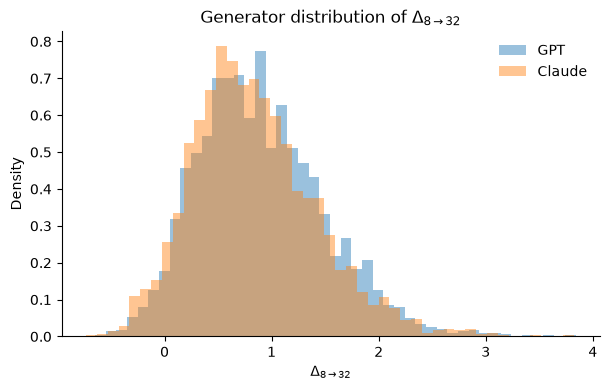

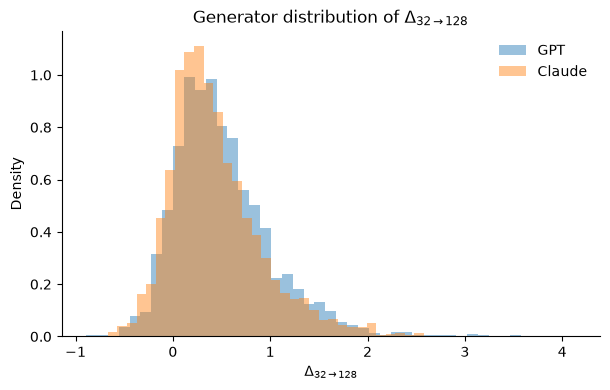

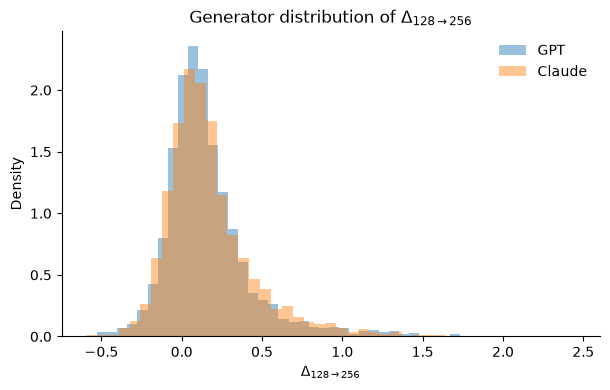

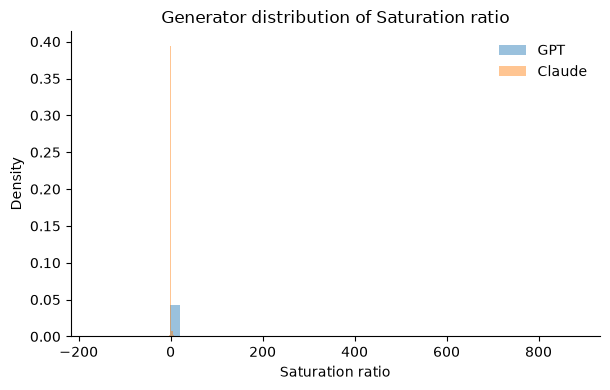

In [10]:
pretty={
    "gain_8_32":r"$\Delta_{8\to32}$",
    "gain_32_128":r"$\Delta_{32\to128}$",
    "gain_128_256":r"$\Delta_{128\to256}$",
    "saturation_ratio":"Saturation ratio"
}

for feature in BANDS:
    fig,ax=plt.subplots(figsize=(6.2,4.0))
    for g in ["gpt","claude"]:
        vals=work.loc[work["generator"]==g,feature].dropna()
        ax.hist(vals,bins=45,density=True,alpha=.45,label=("GPT" if g=="gpt" else "Claude"))
    ax.set_xlabel(pretty[feature]); ax.set_ylabel("Density")
    ax.set_title(f"Generator distribution of {pretty[feature]}")
    ax.legend(frameon=False); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    fig.tight_layout()
    stem=feature.replace("gain_","")
    fig.savefig(FIGURES/f"distance_band_{stem}.pdf",bbox_inches="tight")
    fig.savefig(FIGURES/f"distance_band_{stem}.png",dpi=200,bbox_inches="tight")
    plt.show()


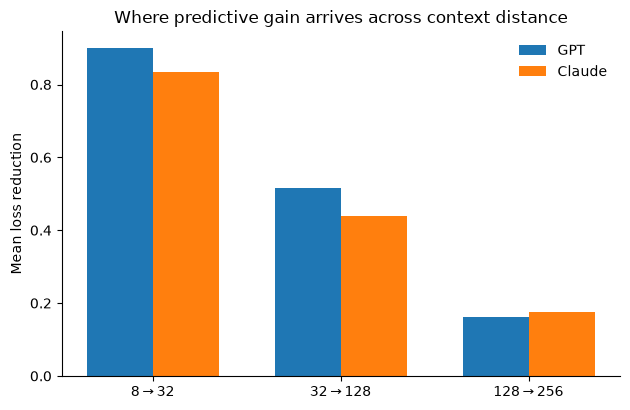

In [11]:
means=work.groupby("generator")[["gain_8_32","gain_32_128","gain_128_256"]].mean()

fig,ax=plt.subplots(figsize=(6.4,4.2))
x=np.arange(3); width=.35
ax.bar(x-width/2,means.loc["gpt"].to_numpy(),width,label="GPT")
ax.bar(x+width/2,means.loc["claude"].to_numpy(),width,label="Claude")
ax.set_xticks(x); ax.set_xticklabels([r"$8\to32$",r"$32\to128$",r"$128\to256$"])
ax.set_ylabel("Mean loss reduction")
ax.set_title("Where predictive gain arrives across context distance")
ax.legend(frameon=False); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES/"distance_band_mean_profile.pdf",bbox_inches="tight")
fig.savefig(FIGURES/"distance_band_mean_profile.png",dpi=200,bbox_inches="tight")
plt.show()


## Interpretation

The most useful positive result would be that one or more band features improve attribution
even after \(L_8\), \(L_{256}\), and strong style controls are already present. That would mean
the **allocation of total context gain across distance bands** contains generator information.

A second useful result would be a clear generator difference in the saturation ratio or in a
specific band that transfers across held-out domains.

Band features are algebraic reparameterizations of the four loss points, so novelty comes from
the generator-dependent **shape/allocation across distance**, not from the arithmetic itself.


In [12]:
def fs(x): return f"{x:+.5f}"

print("GENERATOR DIFFERENCES")
for r in paired_summary.itertuples(index=False):
    print(r.feature,"| mean Claude-GPT",fs(r.mean_claude_minus_gpt),
          "| dz",f"{r.paired_dz:+.3f}","| n",int(r.n_pairs))

print("\nATTRIBUTION BEYOND ENDPOINT LOSSES")
for method in ["Bend+G8_32","Bend+G32_128","Bend+G128_256","Bend+Bands","Bend+Sat"]:
    r=attrib_summary[(attrib_summary["comparison"]==f"{method} vs Bend")&
                     (attrib_summary["metric"]=="auroc")].iloc[0]
    print(method,"| mean ΔAUROC",fs(r.mean_delta),"| median",fs(r.median_delta),
          "| IQR",f"[{fs(r.q25)}, {fs(r.q75)}]","| positive",f"{int(r.positive)}/{int(r.n)}")


GENERATOR DIFFERENCES
gain_8_32 | mean Claude-GPT -0.06571 | dz -0.079 | n 2860
gain_32_128 | mean Claude-GPT -0.07779 | dz -0.109 | n 2860
gain_128_256 | mean Claude-GPT +0.01322 | dz +0.033 | n 2860
saturation_ratio | mean Claude-GPT -0.09081 | dz -0.005 | n 2860

ATTRIBUTION BEYOND ENDPOINT LOSSES
Bend+G8_32 | mean ΔAUROC +0.00011 | median +0.00015 | IQR [+0.00001, +0.00020] | positive 16/20
Bend+G32_128 | mean ΔAUROC -0.00021 | median +0.00000 | IQR [-0.00045, +0.00011] | positive 10/20
Bend+G128_256 | mean ΔAUROC +0.00034 | median +0.00031 | IQR [-0.00019, +0.00102] | positive 13/20
Bend+Bands | mean ΔAUROC +0.00020 | median +0.00031 | IQR [-0.00023, +0.00080] | positive 13/20
Bend+Sat | mean ΔAUROC -0.00022 | median -0.00004 | IQR [-0.00007, +0.00000] | positive 5/20
